# Módulo 3 — Práctica Día 4: repositorios, Herbie, cdsapi y FNL

Ejercicios de la práctica del **Día 4** (ver [`README.md`](../README.md)).
Todas las descargas de este notebook son **reales** (`cdsapi`/ERA5,
`Herbie`/GFS, `wget`/`tcsh` para FNL). En los Ejercicios 2 a 4 se descarga
el **archivo global completo** de cada fuente — así es como los datos
entran al WRF, WPS recorta al dominio real recién en `metgrid`, no antes —
y recién después de la descarga se recorta con `.sel()` a una **estación
real de Perú elegida al azar** (Módulo 5), distinta cada vez que se corre
este notebook. Los archivos globales generados (cientos de MB) **no se
suben al repositorio del curso** — quedan solo en la máquina donde se
descargan (ver `.gitignore`); lo que si viaja con el curso es el código que
los genera. Cada función de descarga guarda en caché local: si el archivo
ya existe, no se vuelve a pedir al servidor.

> **📍 Nota para curso con 2 grupos:** la estación real de Perú se elige con `random.choice(list(coords_peru))`, pensado para que cada participante reciba una distinta. Para 2 grupos fijos (coherente con los Días 1 y 3), restringir la lista antes del sorteo:
> ```python
> ESTACIONES_GRUPO_1 = ["Lima", "Piura", "Tumbes", "Chiclayo"]   # Norte
> ESTACIONES_GRUPO_2 = ["Cuzco", "Arequipa", "Tacna"]             # Sur
> nombre_estacion = random.choice(ESTACIONES_GRUPO_1)  # o GRUPO_2, según el grupo
> ```
> El resto de la celda (`lat_estacion`, `lon_estacion`, `recortar_estacion()`) no cambia.

## Ejercicio 1 — Configuración de credenciales (25 min)

Un archivo `~/.cdsapirc` real tiene este formato (con tu propia URL y
clave, obtenidas de tu perfil en el portal de Copernicus CDS):

```
url: https://cds.climate.copernicus.eu/api
key: <tu-clave-personal>
```

Verificamos que las librerías estén instaladas y sean importables, y que
el archivo de credenciales exista:

In [1]:
import importlib
import os

paquetes = ["cdsapi", "herbie", "xarray", "cfgrib"]
for nombre in paquetes:
    mod = importlib.import_module(nombre)
    version = getattr(mod, "__version__", "version no expuesta")
    print(f"{nombre:10s} instalado OK (version: {version})")

print()
ruta_cdsapirc = os.path.expanduser("~/.cdsapirc")
print(f"~/.cdsapirc existe? -> {os.path.exists(ruta_cdsapirc)}")

cdsapi     instalado OK (version: version no expuesta)


herbie     instalado OK (version: 2026.3.0)
xarray     instalado OK (version: 2026.1.0)
cfgrib     instalado OK (version: 0.9.15.1)

~/.cdsapirc existe? -> True


### Estación asignada (real)

Las 7 estaciones reales de aeropuerto de Perú son las mismas del Módulo 5
(`data/ogimet/coords_peru.json`, coordenadas obtenidas de OGIMET para cada
estación). El docente asigna una a cada participante: escríbela en la celda
siguiente. Así tu resultado es el mismo cada vez que ejecutas el notebook y
puedes compararlo con el de quien tenga tu misma estación.

Se define también una función de recorte reutilizable: un cuadrado de
`±buffer` grados alrededor de la estación, sobre el archivo **global** ya
descargado.

In [ ]:
import json

with open("../../../data/ogimet/coords_peru.json", encoding="utf-8") as f:
    coords_peru = json.load(f)

print("Estaciones disponibles:", list(coords_peru))
nombre_estacion = "Lima"            # ✍️ cambia por la estación que te asignó el docente
lat_estacion = coords_peru[nombre_estacion]["lat"]
lon_estacion = coords_peru[nombre_estacion]["lon"]
print(f"Estación asignada: {nombre_estacion} "
      f"({lat_estacion}, {lon_estacion})")


def recortar_estacion(ds, lat, lon, buffer=3, lon_0_360=False):
    """Recorta un Dataset global a un cuadrado de +/-buffer grados
    alrededor de (lat, lon). lon_0_360=True si la grilla usa 0-360 (GFS/FNL)
    en vez de -180/180 (ERA5)."""
    lon_c = lon % 360 if lon_0_360 else lon
    return ds.sel(latitude=slice(lat + buffer, lat - buffer),
                  longitude=slice(lon_c - buffer, lon_c + buffer))

## Ejercicio 2 — Primera descarga con Herbie (40 min)

Descarga real de GFS: temperatura a 2 m **y** viento a 10 m del mismo
ciclo. Herbie trae el **mensaje GRIB2 completo de esa variable, con
cobertura global** (no descarga el archivo entero de todas las variables,
pero el mensaje de una sola variable ya cubre todo el planeta) — recién
después se recorta con `.sel()`. Se usa una fecha ya archivada + prioridad
explícita de fuente (`["aws", "google"]`) — pedir un ciclo muy reciente
puede colgarse buscando en NOMADS, el servidor operativo de corto plazo.

In [3]:
from herbie import Herbie
import xarray as xr

h = Herbie("2025-03-15 00:00", model="gfs", product="pgrb2.0p25", fxx=0,
           priority=["aws", "google"])

ds_gfs_t2m_global = h.xarray(":TMP:2 m above ground")
print("Descarga real completada -- forma GLOBAL:", dict(ds_gfs_t2m_global.sizes))
print("Atributos GRIB relevantes:",
      {k: v for k, v in ds_gfs_t2m_global.attrs.items() if k.startswith("GRIB_")})

✅ Found ┊ model=gfs ┊ product=pgrb2.0p25 ┊ 2025-Mar-15 00:00 UTC F00 ┊ GRIB2 @ aws ┊ IDX @ local


/home/japq/.conda/envs/jap/lib/python3.13/site-packages/herbie/core.py:1280: UserWarning: Will not remove GRIB file because it previously existed.
  warnings.warn("Will not remove GRIB file because it previously existed.")


/home/japq/.conda/envs/jap/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Descarga real completada -- forma GLOBAL: {'latitude': 721, 'longitude': 1440}
Atributos GRIB relevantes: {'GRIB_edition': 2, 'GRIB_centre': 'kwbc', 'GRIB_centreDescription': 'US National Weather Service - NCEP', 'GRIB_subCentre': 0}


Recortado a Tumbes: {'latitude': 24, 'longitude': 24}


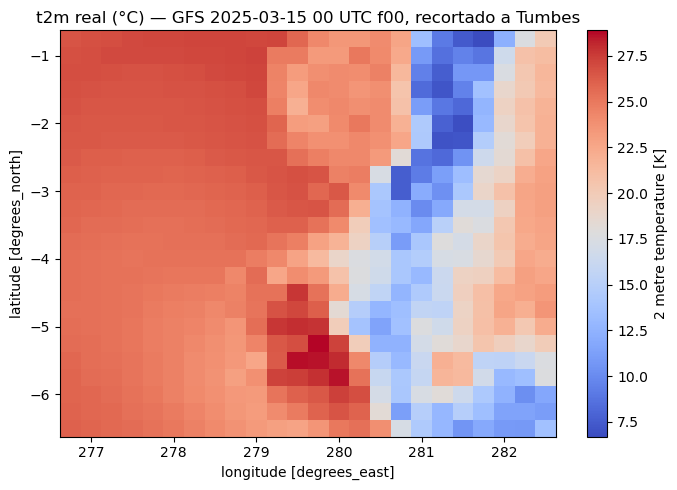

In [4]:
import matplotlib.pyplot as plt

ds_gfs_t2m = recortar_estacion(ds_gfs_t2m_global, lat_estacion, lon_estacion, lon_0_360=True)
print(f"Recortado a {nombre_estacion}:", dict(ds_gfs_t2m.sizes))

fig, ax = plt.subplots(figsize=(7, 5))
(ds_gfs_t2m["t2m"] - 273.15).plot(ax=ax, cmap="coolwarm")
ax.set_title(f"t2m real (°C) — GFS 2025-03-15 00 UTC f00, recortado a {nombre_estacion}")
fig.tight_layout()
plt.show()

**Segunda variable del mismo ciclo: viento a 10 m.** Un pedido real casi
siempre trae varias variables, no una sola — se descarga el viento u
real del mismo ciclo GFS, también global, y se recorta igual.

Variable decodificada: ['u10']
Unidades: m s**-1


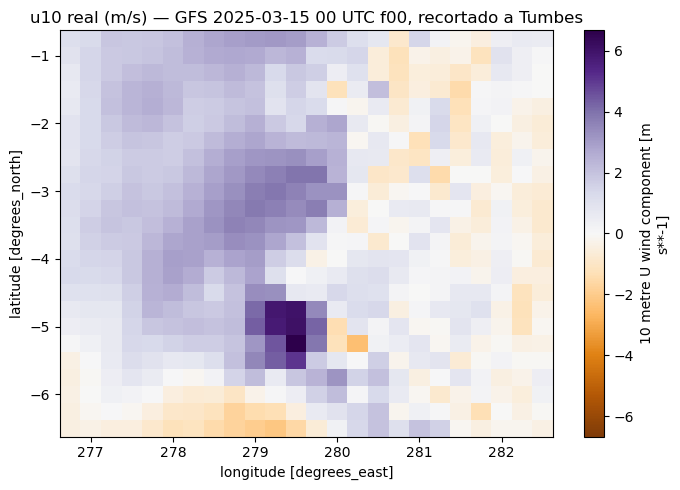

In [5]:
ds_gfs_u10_global = h.xarray(":UGRD:10 m above ground")
ds_gfs_u10 = recortar_estacion(ds_gfs_u10_global, lat_estacion, lon_estacion, lon_0_360=True)

print("Variable decodificada:", list(ds_gfs_u10.data_vars))
print("Unidades:", ds_gfs_u10["u10"].attrs.get("units"))

fig, ax = plt.subplots(figsize=(7, 5))
ds_gfs_u10["u10"].plot(ax=ax, cmap="PuOr")
ax.set_title(f"u10 real (m/s) — GFS 2025-03-15 00 UTC f00, recortado a {nombre_estacion}")
fig.tight_layout()
plt.show()

## Ejercicio 3 — Primera descarga con cdsapi (40 min)

Solicitud real a Copernicus CDS: temperatura **y** presión a nivel del
mar (2 variables, cumpliendo lo que pide el README) en un solo pedido —
**sin restringir `area`**, para que CDS entregue la grilla global completa,
igual que Herbie en el Ejercicio 2. El recorte a la estación asignada se
hace después, en Python, no en la solicitud al servidor.

In [6]:
import cdsapi

def descargar_era5_global(destino, variables, fecha, horas):
    if os.path.exists(destino):
        print(f"Ya existe {destino}, no se vuelve a pedir al servidor.")
        return destino
    anio, mes, dia = fecha.split("-")
    client = cdsapi.Client()
    client.retrieve(
        "reanalysis-era5-single-levels",
        {
            "product_type": "reanalysis",
            "variable": variables,
            "year": anio, "month": mes, "day": dia,
            "time": horas,
            # sin "area": CDS entrega la grilla global completa
            "format": "netcdf",
        },
        destino,
    )
    return destino

archivo_era5 = descargar_era5_global(
    destino="era5_global_dia4.nc",
    variables=["2m_temperature", "mean_sea_level_pressure"],
    fecha="2025-03-15", horas=["00:00", "06:00", "12:00", "18:00"],
)
ds_era5_global = xr.open_dataset(archivo_era5)
print("Archivo real guardado (GLOBAL):", archivo_era5)
print("Forma global:", dict(ds_era5_global.sizes))
print("Variables:", list(ds_era5_global.data_vars))

Ya existe era5_global_dia4.nc, no se vuelve a pedir al servidor.
Archivo real guardado (GLOBAL): era5_global_dia4.nc
Forma global: {'valid_time': 4, 'latitude': 721, 'longitude': 1440}
Variables: ['t2m', 'msl']


Recortado a Tumbes: {'valid_time': 4, 'latitude': 24, 'longitude': 0}


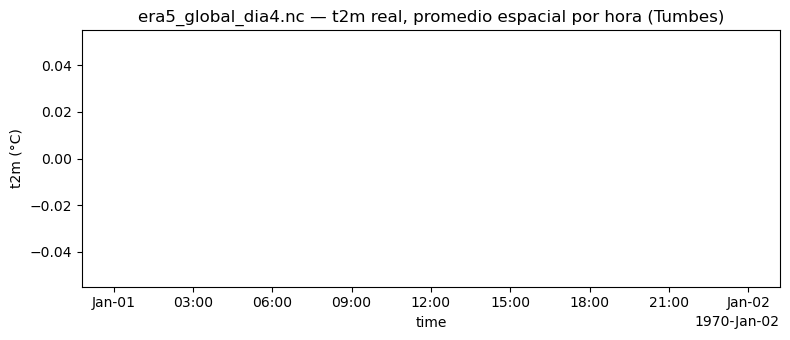

In [7]:
ds_era5 = recortar_estacion(ds_era5_global, lat_estacion, lon_estacion, lon_0_360=False)
print(f"Recortado a {nombre_estacion}:", dict(ds_era5.sizes))

fig, ax = plt.subplots(figsize=(8, 3.5))
(ds_era5["t2m"].mean(dim=["latitude", "longitude"]) - 273.15).plot(ax=ax)
ax.set_ylabel("t2m (°C)")
ax.set_title(f"era5_global_dia4.nc — t2m real, promedio espacial por hora ({nombre_estacion})")
fig.tight_layout()
plt.show()

**Segunda variable de la misma descarga: presión a nivel del mar.**

Unidades de msl: Pa


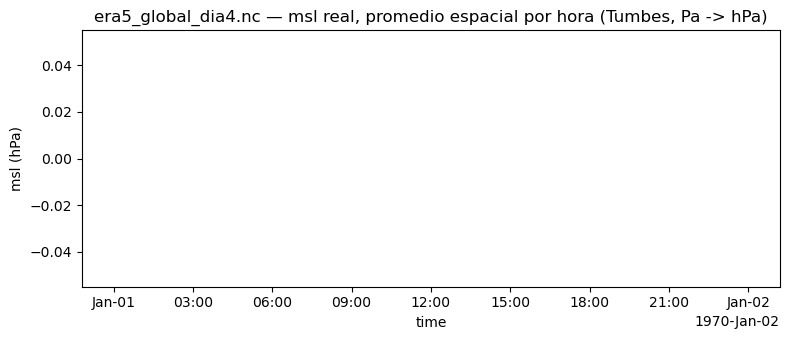

In [8]:
print("Unidades de msl:", ds_era5["msl"].attrs.get("units"))

fig, ax = plt.subplots(figsize=(8, 3.5))
(ds_era5["msl"].mean(dim=["latitude", "longitude"]) / 100).plot(ax=ax, color="tab:purple")
ax.set_ylabel("msl (hPa)")
ax.set_title(f"era5_global_dia4.nc — msl real, promedio espacial por hora ({nombre_estacion}, Pa -> hPa)")
fig.tight_layout()
plt.show()

## Ejercicio 4 — Descarga real de FNL por HTTPS directo (30 min)

A diferencia de Herbie y `cdsapi`, FNL no tiene cliente de Python: se
descarga con un script `csh` parametrizado por fecha
(`data/descarga_FNL.csh`, ya incluido en el repositorio del curso), que
arma una URL por cada paso de pronóstico del ciclo y usa `wget -N` (no
vuelve a descargar si el archivo ya existe):

```
tcsh descarga_FNL.csh 20250315
```

En un laboratorio donde el puerto de datos de GDEX estuviera bloqueado,
este comando podría no completar la descarga aunque el script en sí sea
correcto — es un problema de red del lugar donde se ejecuta, no del
script ni de credenciales (FNL no las requiere). El archivo de este
ejercicio ya fue descargado así para el ciclo **2025-03-15 00 UTC** (mismo
mes que las observaciones de estaciones de Perú del Módulo 5); es
**global** (por eso pesa ~400 MB) y está en `unalm/data/`, fuera del
repositorio de git.

Ignoring index file '../../../data/gdas1.fnl0p25.2025031500.f00.grib2.da267.idx' incompatible with GRIB file


Archivo real (ya descargado, global): {'latitude': 721, 'longitude': 1440}
Recortado a Tumbes: {'latitude': 24, 'longitude': 24}
Valid time: 2025-03-15T00:00:00.000000000


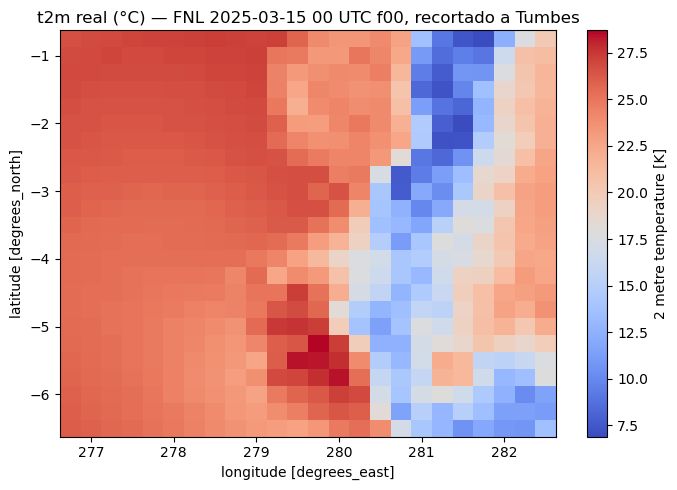

In [9]:
RUTA_DATOS = "../../../data"
archivo_fnl_f00 = os.path.join(RUTA_DATOS, "gdas1.fnl0p25.2025031500.f00.grib2")

ds_fnl_global = xr.open_dataset(
    archivo_fnl_f00, engine="cfgrib",
    backend_kwargs={"filter_by_keys": {"typeOfLevel": "heightAboveGround", "level": 2}},
)
print("Archivo real (ya descargado, global):", dict(ds_fnl_global.sizes))

ds_fnl = recortar_estacion(ds_fnl_global, lat_estacion, lon_estacion, lon_0_360=True)
print(f"Recortado a {nombre_estacion}:", dict(ds_fnl.sizes))
print("Valid time:", str(ds_fnl.valid_time.values))

fig, ax = plt.subplots(figsize=(7, 5))
(ds_fnl["t2m"] - 273.15).plot(ax=ax, cmap="coolwarm")
ax.set_title(f"t2m real (°C) — FNL 2025-03-15 00 UTC f00, recortado a {nombre_estacion}")
fig.tight_layout()
plt.show()

## Ejercicio 4b — Cuarta fuente: estaciones de SENAMHI (15 min)

**Demostración del docente:** descarga una estación con `station-hist` en
su navegador (ver Sección 3c de la teoría): el portal pide pasar una
verificación «no soy un robot», así que la descarga no puede correr sola.

**Tu parte:** trabajar con los archivos que ya están en `data/senamhi/`
(5 estaciones de Lima, marzo de 2025). ¿Qué midió cada estación a la hora
del ciclo GFS que descargaste en el Ejercicio 2 (00 UTC del 15 de marzo), y
qué dice GFS en ese mismo lugar?

In [10]:
import pandas as pd

RUTA_SENAMHI = "../../../data/senamhi/"
with open(RUTA_SENAMHI + "estaciones_lima.json", encoding="utf-8") as f:
    estaciones_senamhi = json.load(f)

filas = []
for e in estaciones_senamhi:
    d = pd.read_csv(RUTA_SENAMHI + e["archivo"], sep=";", dtype=str)
    # SENAMHI usa hora local (UTC-5): las 00 UTC del 15 son las 19:00 del 14
    medido = d[(d["Día"] == "14") & (d["Hora"] == "19:00")]["Temperatura (°C)"].iloc[0]
    gfs = float(ds_gfs_t2m_global["t2m"].sel(latitude=e["lat"], longitude=e["lon"] % 360,
                                              method="nearest")) - 273.15
    filas.append({"estacion": e["nombre"], "altura_m": e["alt_m"],
                  "horas_en_archivo": len(d), "medido_C": float(medido), "GFS_C": round(gfs, 2)})

tabla_senamhi = pd.DataFrame(filas).set_index("estacion")
tabla_senamhi["GFS_menos_medido"] = (tabla_senamhi["GFS_C"] - tabla_senamhi["medido_C"]).round(2)
tabla_senamhi

,altura_m,horas_en_archivo,medido_C,GFS_C,GFS_menos_medido
estacion,,,,,
San Martin De Porres,56,737,22.5,23.99,1.49
Campo De Marte,117,744,21.4,23.99,2.59
Von Humboldt,247,743,22.6,23.99,1.39
Ceres,339,737,24.3,23.99,-0.31
Ñaña,553,744,24.2,20.29,-3.91


Dos cosas para notar:

- **`horas_en_archivo`:** marzo tiene 744 horas, pero algunos archivos
  traen menos. Mañana (Día 5) se verifica esto igual que se verifica un
  NetCDF.
- **GFS da exactamente el mismo valor en 4 de las 5 estaciones:** caen en
  la misma celda de 25 km. La estación, en cambio, mide lo que pasa en su punto.
  Esa diferencia se estudia en el Módulo 6.

## Ejercicio 5 — Función parametrizada de descarga (35 min)

Se separa "qué se quiere descargar" (parámetros) de "cómo se obtiene"
(cuerpo de la función), tal como se plantea en el README — ahora sobre la
descarga real, con caché para no repetir pedidos ya satisfechos.

**Nota:** a diferencia de los Ejercicios 2 a 4 (donde se descargó el globo
completo porque GFS y FNL no permiten pedir un recorte al servidor — solo
se puede recortar después, en Python), aquí se practica el patrón
alternativo de pedir un **área acotada directamente al servidor** vía el
parámetro `area`, algo que `cdsapi` sí permite. Cuando el dominio del WRF
ya está definido de antemano, pedir el recorte al servidor es la práctica
real más eficiente — no tiene sentido bajar el planeta entero si se sabe
de antemano qué región se va a usar. Este patrón acotado es justamente el
que se retoma en el Día 5 para la función `obtener_entrada_wrf()`.

In [ ]:
import os

import cdsapi
import pandas as pd
import xarray as xr


def descargar_era5(fecha_inicio, fecha_fin, area, variables, destino):
    """Descarga real de ERA5 vía cdsapi. area=[norte, oeste, sur, este].
    Si `destino` ya existe, no vuelve a pedir al servidor."""
    if os.path.exists(destino):
        print(f"Ya existe {destino}, no se vuelve a pedir al servidor.")
        return destino

    dias = pd.date_range(fecha_inicio, fecha_fin, freq="D")
    if len(dias) == 0:
        raise ValueError(f"fecha_fin ({fecha_fin}) es anterior a fecha_inicio ({fecha_inicio}).")
    if (dias[0].year, dias[0].month) != (dias[-1].year, dias[-1].month):
        raise ValueError("El periodo cruza de un mes a otro: CDS necesita un pedido por mes.")
    horas = [f"{h:02d}:00" for h in range(0, 24, 6)]  # cada 6 h, liviano

    client = cdsapi.Client()
    client.retrieve(
        "reanalysis-era5-single-levels",
        {
            "product_type": "reanalysis",
            "variable": variables,
            "year": dias[0].strftime("%Y"),
            "month": dias[0].strftime("%m"),
            "day": [d.strftime("%d") for d in dias],   # todos los días del periodo
            "time": horas,
            "area": area,
            "format": "netcdf",
        },
        destino,
    )
    return destino


caso_a = descargar_era5(
    fecha_inicio="2024-12-13", fecha_fin="2024-12-13",
    area=[0, -82, -18, -68], variables=["2m_temperature"],
    destino="caso_a_diciembre.nc",
)
caso_b = descargar_era5(
    fecha_inicio="2024-06-10", fecha_fin="2024-06-10",
    area=[-5, -82, -15, -68], variables=["2m_temperature"],
    destino="caso_b_junio.nc",
)

print("Caso A:", caso_a, "->", xr.open_dataset(caso_a).sizes)
print("Caso B:", caso_b, "->", xr.open_dataset(caso_b).sizes)

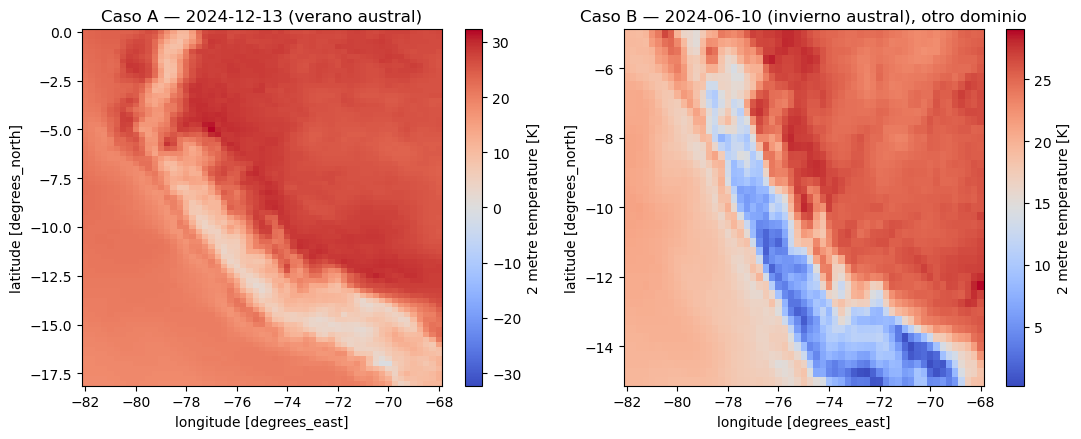

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
(xr.open_dataset(caso_a)["t2m"].isel(valid_time=0) - 273.15).plot(ax=axes[0], cmap="coolwarm")
axes[0].set_title("Caso A — 2024-12-13 (verano austral)")
(xr.open_dataset(caso_b)["t2m"].isel(valid_time=0) - 273.15).plot(ax=axes[1], cmap="coolwarm")
axes[1].set_title("Caso B — 2024-06-10 (invierno austral), otro dominio")
fig.tight_layout()
plt.show()

## Cierre

Entregable del día: este notebook + los archivos reales generados
(`demo_era5_real.nc` del teórico, `era5_global_dia4.nc`,
`caso_a_diciembre.nc`, `caso_b_junio.nc`, además del FNL global ya en
`unalm/data/`). Ninguno de estos archivos viaja al repositorio del curso
(ver `.gitignore`) — son datos reales pero pesados, propios de cada
máquina donde se corre el notebook, igual que los `wrfout` del proyecto
`bigua`. Continuar con
[`03_practica_dia5_integridad.ipynb`](03_practica_dia5_integridad.ipynb).